# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

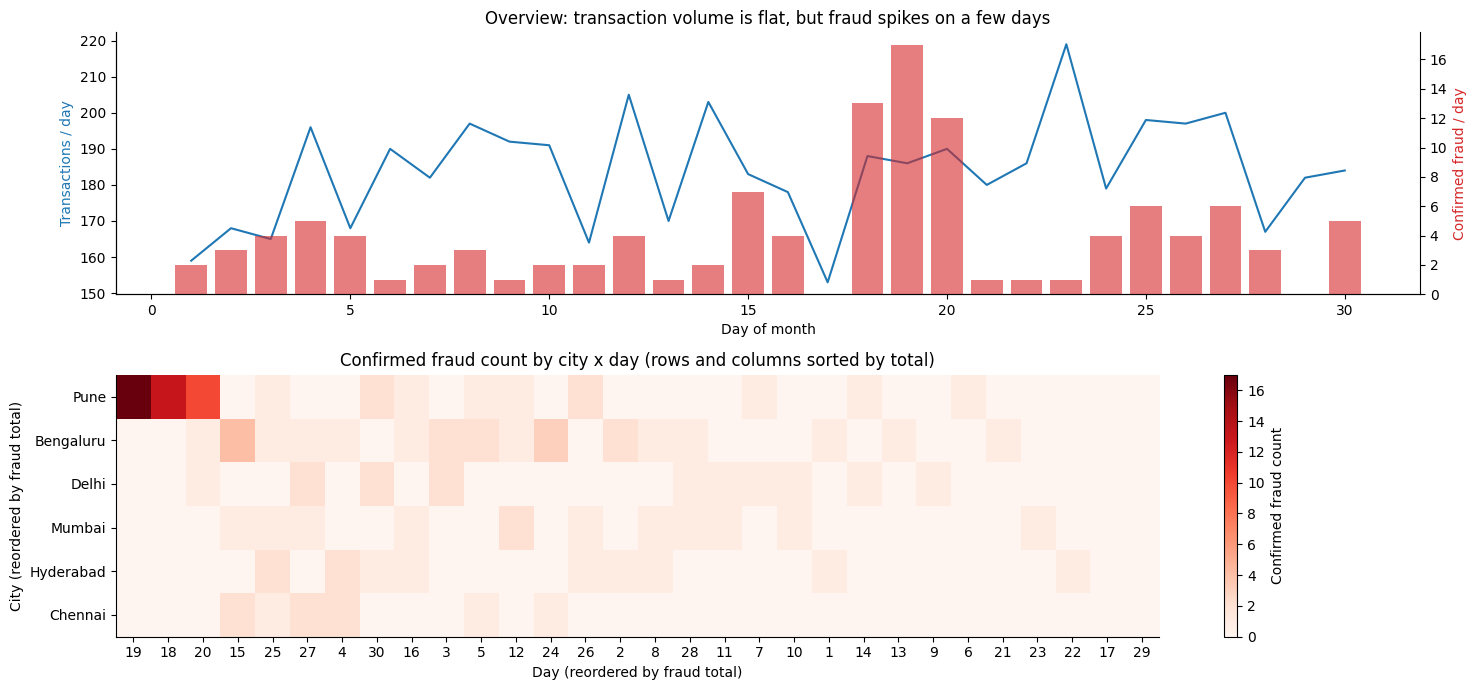

Top (city, day) cells by confirmed fraud:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1: daily counts + daily confirmed fraud (second axis)
daily_n = tx.groupby("day").size()
daily_f = tx.groupby("day").is_fraud.sum()
ax = axes[0]
ax.plot(daily_n.index, daily_n.values, color="tab:blue", lw=1.5, label="Transactions")
ax.set_xlabel("Day of month"); ax.set_ylabel("Transactions / day", color="tab:blue")
ax2 = ax.twinx()
ax2.bar(daily_f.index, daily_f.values, color="tab:red", alpha=0.6, label="Confirmed fraud")
ax2.set_ylabel("Confirmed fraud / day", color="tab:red"); ax2.spines["right"].set_visible(True)
ax.set_title("Overview: transaction volume is flat, but fraud spikes on a few days")

# TODO 2: city x day matrix of confirmed-fraud counts, reordered by totals
heat = tx[tx.is_fraud == 1].pivot_table(index="city", columns="day", values="txn_id", aggfunc="count", fill_value=0)
heat = heat.reindex(columns=range(tx.day.min(), tx.day.max() + 1), fill_value=0)
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index,
                heat.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat.values, aspect="auto", cmap="Reds")
axes[1].set_xticks(range(heat.shape[1])); axes[1].set_xticklabels(heat.columns)
axes[1].set_yticks(range(heat.shape[0])); axes[1].set_yticklabels(heat.index)
axes[1].set_xlabel("Day (reordered by fraud total)"); axes[1].set_ylabel("City (reordered by fraud total)")
axes[1].set_title("Confirmed fraud count by city x day (rows and columns sorted by total)")
plt.colorbar(im, ax=axes[1], label="Confirmed fraud count")

plt.tight_layout(); plt.show()

# TODO 3: top (city, day) cells
top = tx[tx.is_fraud == 1].groupby(["city", "day"]).size().sort_values(ascending=False).head(5)
print("Top (city, day) cells by confirmed fraud:"); print(top.to_string())


**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_

The overview showed that overall transaction volume is flat but confirmed fraud is concentrated in one place and time: Pune on days 18-20 (17, 13 and 10 cases, 40 of the 120 frauds), something a list of alerts sorted by detector score would never show because it is a flat list of single transactions with no city or day structure. It was found by the reordered matrix (Slide 39): sorting the city x day matrix by row and column totals pushes the hot cells into one corner, and it follows the overview-first step of Shneiderman's mantra (Slide 38 / 30).

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

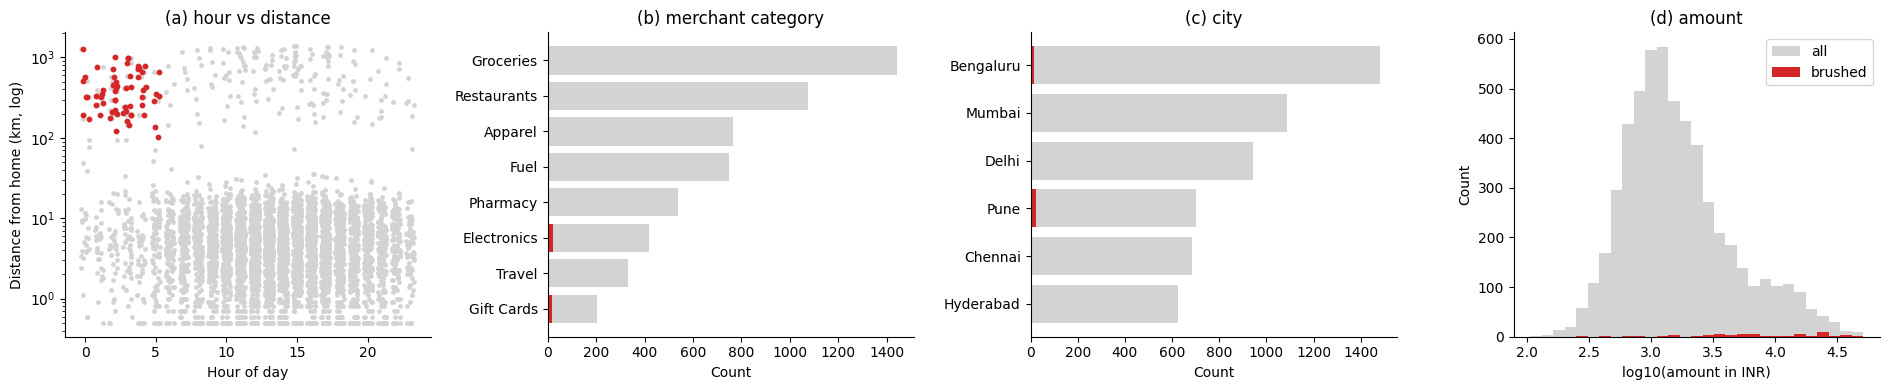

Brushed: 61 transactions
Fraud rate in brush: 86.9% vs overall 2.17%
Share of ALL fraud captured by the brush: 44.2%


In [3]:
# TODO 1
brush = tx.night & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2
grey, red = "lightgrey", "tab:red"
sub = tx[brush]
# (a) hour vs distance (log y)
axes[0].scatter(tx.hour + np.random.uniform(-0.3, 0.3, len(tx)), tx.distance_from_home_km.clip(lower=0.5), s=6, c=grey)
axes[0].scatter(sub.hour + np.random.uniform(-0.3, 0.3, len(sub)), sub.distance_from_home_km, s=10, c=red)
axes[0].set_yscale("log"); axes[0].set_xlabel("Hour of day"); axes[0].set_ylabel("Distance from home (km, log)")
axes[0].set_title("(a) hour vs distance")
# (b) merchant category counts
cats = tx.merchant_category.value_counts().index
y = np.arange(len(cats))
axes[1].barh(y, tx.merchant_category.value_counts()[cats].values, color=grey)
axes[1].barh(y, sub.merchant_category.value_counts().reindex(cats, fill_value=0).values, color=red)
axes[1].set_yticks(y); axes[1].set_yticklabels(cats); axes[1].invert_yaxis(); axes[1].set_xlabel("Count"); axes[1].set_title("(b) merchant category")
# (c) city counts
cities = tx.city.value_counts().index
y = np.arange(len(cities))
axes[2].barh(y, tx.city.value_counts()[cities].values, color=grey)
axes[2].barh(y, sub.city.value_counts().reindex(cities, fill_value=0).values, color=red)
axes[2].set_yticks(y); axes[2].set_yticklabels(cities); axes[2].invert_yaxis(); axes[2].set_xlabel("Count"); axes[2].set_title("(c) city")
# (d) log10 amount histogram
bins = np.linspace(np.log10(tx.amount_inr.min()), np.log10(tx.amount_inr.max()), 30)
axes[3].hist(np.log10(tx.amount_inr), bins=bins, color=grey, label="all")
axes[3].hist(np.log10(sub.amount_inr), bins=bins, color=red, label="brushed")
axes[3].set_xlabel("log10(amount in INR)"); axes[3].set_ylabel("Count"); axes[3].set_title("(d) amount"); axes[3].legend()

plt.tight_layout(); plt.show()

# TODO 3
fr_brush = tx.loc[brush, "is_fraud"].mean()
fr_all = tx.is_fraud.mean()
share = tx.loc[brush, "is_fraud"].sum() / tx.is_fraud.sum()
print(f"Brushed: {brush.sum()} transactions")
print(f"Fraud rate in brush: {fr_brush:.1%} vs overall {fr_all:.2%}")
print(f"Share of ALL fraud captured by the brush: {share:.1%}")


**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_

The brush has a fraud rate of 86.9% (against 2.17% overall) but it captures only 44.2% of all fraud, so more than half of the fraud (including a lot of daytime and short-distance fraud) is outside the rule. Relying on the rule alone would give very precise alerts but miss most of the fraud, so it has high precision but low recall. The linked views hinted where the rest is: the city view (Pune is the largest bar) and the category and amount views, where the confirmed fraud is concentrated in Electronics and Gift Cards with large amounts, pointing to a pattern that is not just "night and far from home".

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1
def run_filter():
    return ((big.detector_score >= 0.6) & (big.amount_inr > 3000)).sum()
times = []
for _ in range(5):
    t0 = time.perf_counter(); run_filter(); times.append(time.perf_counter() - t0)
best_s = min(times)

# TODO 2
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / (best_s / len(big))

# TODO 3
t_50m = best_s / len(big) * 50_000_000
skip_pct = max(0.0, (1 - 0.1 / t_50m) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")


1,004,640 rows in 3.8 ms -> 0.0038 us/row -> max 26,398,297 rows in 0.1 s
50M rows -> 0.19 s; must skip 47.2% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_

A reduce technique is aggregation (binning or pre-aggregation, e.g. precomputed counts per score bin, city and day), so the slider only has to filter a small summary table instead of 50M rows (sampling or filtering would be other options). What the analyst loses is the individual transactions: they can no longer see single outliers or rare cases (only about 2% of rows are fraud), and the view is limited to the bins that were precomputed, so they would need a details-on-demand step to get back to the raw rows.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

,threshold,alerts,TP,FP,FN,precision,recall,F1
0,0.05,2012,114,1898,6,0.057,0.950,0.107
1,0.10,1167,111,1056,9,0.095,0.925,0.172
2,0.15,786,110,676,10,0.140,0.917,0.243
3,0.20,596,106,490,14,0.178,0.883,0.296
4,0.25,471,105,366,15,0.223,0.875,0.355
5,0.30,401,104,297,16,0.259,0.867,0.399
6,0.35,355,104,251,16,0.293,0.867,0.438
7,0.40,319,104,215,16,0.326,0.867,0.474
8,0.45,283,104,179,16,0.367,0.867,0.516
9,0.50,260,101,159,19,0.388,0.842,0.532


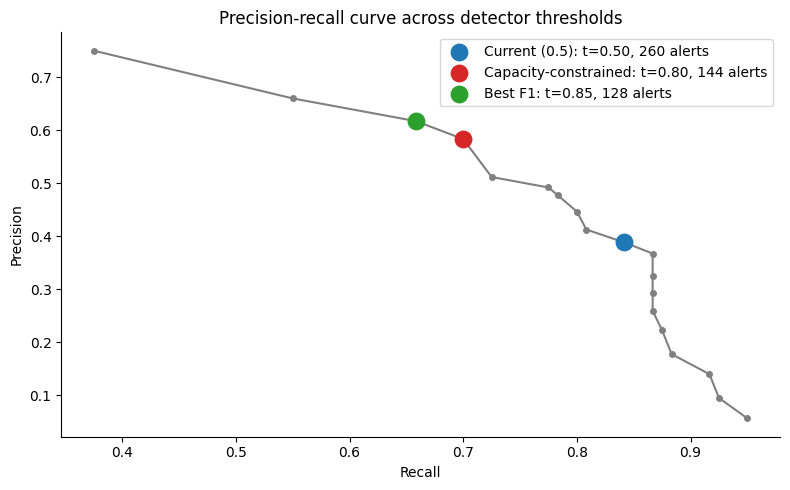

Recommendation: set threshold to 0.80 -> 144 alerts/month (precision 0.58, recall 0.70); current 0.50 gives 260 alerts, best-F1 is 0.85 (128 alerts, F1 0.64).


In [5]:
rows = []
# TODO 1
for th in np.round(np.arange(0.05, 0.96, 0.05), 2):
    flag = tx.detector_score >= th
    tp = int((flag & (tx.is_fraud == 1)).sum())
    fp = int((flag & (tx.is_fraud == 0)).sum())
    fn = int((~flag & (tx.is_fraud == 1)).sum())
    prec = tp / (tp + fp) if (tp + fp) else np.nan
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (tp > 0) else 0.0
    rows.append(dict(threshold=th, alerts=int(flag.sum()), TP=tp, FP=fp, FN=fn, precision=prec, recall=rec, F1=f1))


pr = pd.DataFrame(rows)
display(pr.round(3))

# TODO 2
ok = pr[pr.alerts <= 150]
capacity_choice = ok.loc[ok.recall.idxmax()]
best_f1 = pr.loc[pr.F1.idxmax()]
current = pr[pr.threshold == 0.5].iloc[0]

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "-o", color="gray", ms=4)
for lbl, r, col in [("Current (0.5)", current, "tab:blue"),
                    ("Capacity-constrained", capacity_choice, "tab:red"),
                    ("Best F1", best_f1, "tab:green")]:
    ax.scatter(r.recall, r.precision, s=140, color=col, zorder=3, label=f"{lbl}: t={r.threshold:.2f}, {int(r.alerts)} alerts")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Precision-recall curve across detector thresholds"); ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
print(f"Recommendation: set threshold to {capacity_choice.threshold:.2f} -> {int(capacity_choice.alerts)} alerts/month "
      f"(precision {capacity_choice.precision:.2f}, recall {capacity_choice.recall:.2f}); "
      f"current 0.50 gives {int(current.alerts)} alerts, best-F1 is {best_f1.threshold:.2f} ({int(best_f1.alerts)} alerts, F1 {best_f1.F1:.2f}).")


**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_

The Head of Fraud Ops should make the call, with the model supplying the numbers. Best F1 (about 0.85, 128 alerts) and the capacity-constrained choice (0.80, 144 alerts, higher recall) are both within the 150 limit, and choosing between them is a business trade-off about the cost of a missed fraud versus investigator time and customer friction, which the model cannot know. Visual analytics keeps a human in the loop (Slides 35-37) because the person can see the precision-recall curve, steer the threshold, see the consequences immediately, bring context the data does not contain, and remain accountable for the decision.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# TODO 1
flagged = tx[tx.detector_score >= 0.3]
fig1 = px.scatter(flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
                  color_discrete_map={"legitimate": "lightgrey", "confirmed fraud": "red"},
                  hover_data={"txn_id": True, "customer_id": True, "city": True, "merchant_category": True,
                              "distance_from_home_km": True, "detector_score": ":.3f"},
                  title=f"Flagged transactions (score >= 0.3): {len(flagged)} cases")
fig1.update_layout(dragmode="select")
fig1.show()

# TODO 2: drill-down sunburst city -> category, sized by count, coloured by fraud rate
g = tx.groupby(["city", "merchant_category"]).agg(count=("txn_id", "size"), fraud_rate=("is_fraud", "mean")).reset_index()
fig2 = px.sunburst(g, path=["city", "merchant_category"], values="count", color="fraud_rate",
                   color_continuous_scale="Reds", title="Drill-down: city -> merchant category (colour = fraud rate)")
fig2.show()


**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_

Tooltips show one case at a time, so to understand 400 flagged cases the investigator would have to hover over each point and remember what they saw, which is slow and not an overview (Slide 23 says details come after the overview, not instead of it). The views that fix this are the overview ones from this notebook: the city x day heatmap and the sunburst (or the linked brushed views from Task 2), which show where the cases concentrate so the tooltip is used only for the few cases worth inspecting.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Fraud rate inside window: 37.4% (40/107) | outside: 1.48% | chi-square p = 1.06e-136
  Pune, days 18-20: 37.38% (40/107)
  Pune, other days: 1.85% (11/593)
  Other cities, days 18-20: 0.44% (2/457)
  Rest: 1.54% (67/4363)


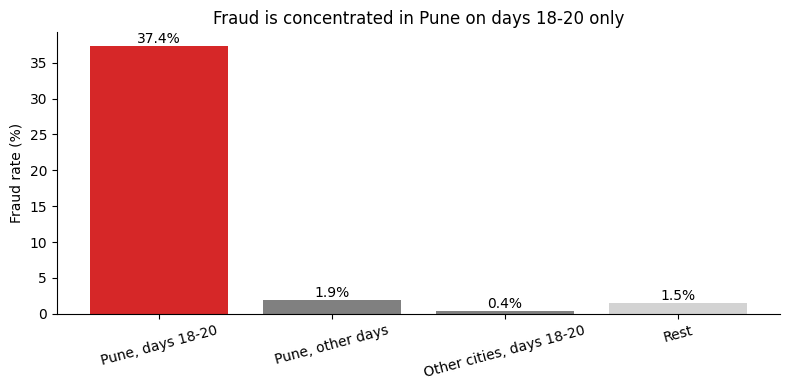

Verdict: hypothesis SURVIVES - fraud is confined to Pune on days 18-20; neither Pune on other days nor other cities on the same days show elevated fraud, so it is a localized burst consistent with a ring (not a city-wide or date-wide effect).


In [7]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis: a fraud ring in Pune on days 18-20
in_window = (tx.city == "Pune") & tx.day.between(18, 20)

# TODO 2
ct_ = pd.crosstab(in_window, tx.is_fraud)
chi2, p, _, _ = chi2_contingency(ct_)
rate_in, rate_out = tx.loc[in_window, "is_fraud"].mean(), tx.loc[~in_window, "is_fraud"].mean()
print(f"Fraud rate inside window: {rate_in:.1%} ({tx.loc[in_window,'is_fraud'].sum()}/{in_window.sum()}) | outside: {rate_out:.2%} | chi-square p = {p:.2e}")

# TODO 3: counter-example searches
same_city_other_days = (tx.city == "Pune") & ~tx.day.between(18, 20)
other_cities_same_days = (tx.city != "Pune") & tx.day.between(18, 20)
rest = (tx.city != "Pune") & ~tx.day.between(18, 20)
groups = {"Pune, days 18-20": in_window, "Pune, other days": same_city_other_days,
          "Other cities, days 18-20": other_cities_same_days, "Rest": rest}
rates = {k: tx.loc[m, "is_fraud"].mean() for k, m in groups.items()}
for k, m in groups.items():
    print(f"  {k}: {rates[k]:.2%} ({tx.loc[m,'is_fraud'].sum()}/{m.sum()})")

# TODO 4
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(list(rates), [v * 100 for v in rates.values()], color=["tab:red", "grey", "grey", "lightgrey"])
ax.bar_label(bars, fmt="%.1f%%"); ax.set_ylabel("Fraud rate (%)"); ax.tick_params(axis="x", rotation=15)
ax.set_title("Fraud is concentrated in Pune on days 18-20 only")
plt.tight_layout(); plt.show()

# TODO 5
supported = p < 0.001 and rates["Pune, other days"] < 0.05 and rates["Other cities, days 18-20"] < 0.05
print("Verdict: " + ("hypothesis SURVIVES - fraud is confined to Pune on days 18-20; neither Pune on other days nor other cities "
      "on the same days show elevated fraud, so it is a localized burst consistent with a ring (not a city-wide or date-wide effect)."
      if supported else "hypothesis REJECTED - a counter-example group is also elevated."))


**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_

The "other cities, same days" search would have killed the ring hypothesis if other cities had also been elevated on days 18-20: that would mean a date-wide event (for example a data breach, a compromised merchant or a campaign hitting every city, or a detector or labelling change on those days) rather than something local to Pune. It came out at 0.44%, so that explanation is ruled out. The "same city, other days" search would similarly have supported a chronic city-level problem; it came out at 1.85%, close to the 1.54% baseline.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

Last month 120 of 5,520 transactions (2.2%) were confirmed fraud, and 40 of them were concentrated in Pune on days 18-20 (a 37.4% fraud rate in that window against about 1.5% elsewhere, chi-square p about 1e-136), so it is a localized burst consistent with a ring. I recommend moving the threshold from 0.50 (260 alerts, above the 150 capacity) to 0.80, which gives 144 alerts with precision 0.58 and recall 0.70; the best-F1 threshold of 0.85 gives 128 alerts but loses recall, so the Head of Fraud Ops, not the model, should make this human-in-the-loop trade-off. The first interactive view to build is the city x day overview heatmap linked (brushed) to the flagged-case scatter with tooltips, because it applies overview first, then filter, then details-on-demand, and the dynamic filter stays instant (about 0.07 s on this machine even at 50M rows with a simple filter, otherwise use pre-aggregation to stay under 0.1 s). The feedback loop to add (Slide 51) is to feed the investigators' confirmed labels back each month to retrain and recalibrate the detector, including features such as city-day bursts, high amounts and Electronics/Gift Cards.